In [1]:
import pandas as pd

prices = pd.read_csv("../data/prices_raw.csv", index_col=0, parse_dates=True)
print(prices.shape)
print(prices.index[:3])

(4248, 23)
DatetimeIndex(['2010-01-04', '2010-01-05', '2010-01-06'], dtype='datetime64[us]', name='Date', freq=None)


In [2]:
print(prices.isna().sum().sum())
print(prices.index.is_unique, prices.index.is_monotonic_increasing)

0
True True


## Data validation log
- Source: yfinance (Yahoo Finance), adjusted daily close, 23 ETFs, 2010-01-04 to 2026-11-19
- Missing values: none; no late starters
- Impossible values (zero/negative): none
- Extreme moves: top 15 scaled moves all tied to real events (March 2020, April 2020, Jan 2026 silver crash)
- Stale prices: HYG 2026-01-12 to 2026-01-15 identical closes, likely stale feed; does not touch a month-end; left as is
- Dates: unique and sorted
- Second-source cross-check: not done (limitation)
- Saved untouched as data/prices_raw.csv

In [3]:
monthly_prices = prices.resample("ME").last()
print(monthly_prices.shape)
monthly_prices.head()

(203, 23)


,DBC,EEM,EFA,GLD,HYG,IEF,IWM,LQD,QQQ,SLV,...,VNQ,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-31,19.182981,27.062700,31.990517,105.959999,32.691334,61.576218,48.019619,56.688694,37.060703,15.900000,...,21.961020,10.557775,15.794269,8.571465,20.124590,8.427861,16.720028,8.328128,23.540150,11.811800
2010-02-28,19.977690,27.543432,32.075851,109.430000,33.303757,61.780605,50.168556,56.975906,38.766922,16.070000,...,23.187147,11.034175,16.269547,8.873700,21.197699,8.721391,17.249708,8.218135,23.630451,12.469603
2010-03-31,19.884693,29.777462,34.124031,108.949997,34.014294,61.127674,54.297764,57.347317,41.756226,17.139999,...,25.549164,11.907656,16.727835,9.663362,23.040398,9.317913,17.899576,8.439251,24.260775,13.443087
2010-04-30,20.662495,29.727957,33.166988,115.360001,34.668873,62.137932,57.381054,58.441429,42.692596,18.260000,...,27.375980,11.932231,17.422892,9.790589,24.021318,9.434888,17.707306,8.661187,23.316917,14.253599
2010-05-31,18.565809,26.935444,29.454676,118.879997,33.047920,63.960571,53.056450,57.676830,39.536617,18.030001,...,25.915569,10.794827,15.427887,8.893929,21.830856,8.728988,16.886995,8.183172,21.799198,13.250688


In [4]:
monthly_returns = monthly_prices.pct_change()

In [5]:
monthly_returns.head()

,DBC,EEM,EFA,GLD,HYG,IEF,IWM,LQD,QQQ,SLV,...,VNQ,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-02-28,0.041428,0.017764,0.002668,0.032748,0.018733,0.003319,0.044751,0.005066,0.046038,0.010692,...,0.055832,0.045123,0.030092,0.035261,0.053323,0.034828,0.031679,-0.013207,0.003836,0.055690
2010-03-31,-0.004655,0.081109,0.063854,-0.004386,0.021335,-0.010569,0.082307,0.006519,0.077110,0.066584,...,0.101867,0.079161,0.028168,0.088989,0.086929,0.068398,0.037674,0.026906,0.026674,0.078069
2010-04-30,0.039116,-0.001663,-0.028046,0.058834,0.019244,0.016527,0.056785,0.019079,0.022425,0.065344,...,0.071502,0.002064,0.041551,0.013166,0.042574,0.012554,-0.010742,0.026298,-0.038905,0.060292
2010-05-31,-0.101473,-0.093936,-0.111928,0.030513,-0.046755,0.029332,-0.075366,-0.013083,-0.073923,-0.012596,...,-0.053346,-0.095322,-0.114505,-0.091584,-0.091188,-0.074818,-0.046326,-0.055190,-0.065091,-0.070362


In [6]:
monthly_returns.tail()

,DBC,EEM,EFA,GLD,HYG,IEF,IWM,LQD,QQQ,SLV,...,VNQ,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,,,,,,,,,,,
2026-07-31,0.104651,-0.063149,0.016365,0.008578,-0.001520,-0.013887,-0.030787,-0.022431,-0.065739,-0.020759,...,0.026133,-0.007869,0.121258,0.062115,-0.029099,-0.079624,0.023835,-0.021835,0.024518,-0.010147
2026-08-31,0.062818,0.045717,0.017712,0.099263,0.009027,0.001166,0.009375,0.003951,0.041817,0.148396,...,-0.025366,0.044815,0.074055,0.013523,-0.026190,0.063587,-0.000823,-0.047802,0.049154,0.004307
2026-09-30,0.032588,-0.003432,-0.033132,-0.067529,-0.027276,-0.033525,-0.052101,-0.033905,0.033178,-0.093464,...,-0.062553,-0.071472,-0.032746,-0.071409,-0.043974,0.050823,-0.045304,-0.059200,-0.008652,-0.064416
2026-10-31,0.039913,-0.086091,-0.005005,-0.065802,0.007311,0.030977,0.005182,0.024857,-0.066615,-0.181802,...,0.048087,0.082957,0.138537,0.058240,0.002515,-0.082963,0.109429,0.101166,0.097672,0.060088
2026-11-30,-0.127641,-0.117955,-0.069943,-0.092501,-0.009074,0.002198,-0.081337,-0.001733,-0.118814,-0.171076,...,-0.014690,-0.083428,-0.135818,-0.034330,-0.065890,-0.169907,0.011631,-0.017039,-0.041272,-0.025308


In [7]:
monthly_prices = monthly_prices.iloc[:-1]
monthly_returns = monthly_returns.iloc[:-1]

In [8]:
print(monthly_prices.tail())

                  DBC        EEM         EFA         GLD        HYG  \
Date                                                                  
2026-06-30  26.660000  68.410004  103.879997  368.380005  78.029465   
2026-07-31  29.450001  64.089996  105.580002  371.540009  77.910858   
2026-08-31  31.299999  67.019997  107.449997  408.420013  78.614159   
2026-09-30  32.320000  66.790001  103.889999  380.839996  76.469917   
2026-10-31  33.610001  61.040001  103.370003  355.779999  77.028999   

                  IEF         IWM         LQD         QQQ        SLV  ...  \
Date                                                                  ...   
2026-06-30  92.962349  299.667358  106.892448  735.633484  53.470001  ...   
2026-07-31  91.671341  290.441437  104.494720  687.273865  52.360001  ...   
2026-08-31  91.778236  293.164307  104.907593  716.013916  60.130001  ...   
2026-09-30  88.701340  277.890015  101.350700  739.770020  54.509998  ...   
2026-10-31  91.448997  279.329987  103.8

In [9]:
print(monthly_returns.tail())

                 DBC       EEM       EFA       GLD       HYG       IEF  \
Date                                                                     
2026-06-30 -0.095658  0.002414  0.006907 -0.116849  0.000864  0.002512   
2026-07-31  0.104651 -0.063149  0.016365  0.008578 -0.001520 -0.013887   
2026-08-31  0.062818  0.045717  0.017712  0.099263  0.009027  0.001166   
2026-09-30  0.032588 -0.003432 -0.033132 -0.067529 -0.027276 -0.033525   
2026-10-31  0.039913 -0.086091 -0.005005 -0.065802  0.007311  0.030977   

                 IWM       LQD       QQQ       SLV  ...       VNQ       XLB  \
Date                                                ...                       
2026-06-30  0.036961  0.001129 -0.001491 -0.217474  ...  0.016509 -0.002540   
2026-07-31 -0.030787 -0.022431 -0.065739 -0.020759  ...  0.026133 -0.007869   
2026-08-31  0.009375  0.003951  0.041817  0.148396  ... -0.025366  0.044815   
2026-09-30 -0.052101 -0.033905  0.033178 -0.093464  ... -0.062553 -0.071472   
2026-10

In [13]:
monthly_returns.shape

(202, 23)

In [14]:
annual_vol = monthly_returns.std() * 12 ** 0.5
(annual_vol * 100).round(1).sort_values()

IEF     6.4
LQD     7.3
HYG     7.4
XLP    12.3
TLT    13.6
XLV    13.8
SPY    14.3
XLU    14.4
EFA    15.4
GLD    16.7
VNQ    17.2
DBC    17.3
QQQ    17.6
XLI    17.7
EEM    18.3
XLY    18.4
XLF    18.5
XLK    18.7
XLB    18.9
IWM    19.5
XLE    26.7
SLV    32.3
USO    37.8
dtype: float64

In [15]:
corr = monthly_returns.corr()
corr["SPY"].sort_values()

TLT   -0.083631
IEF   -0.040941
GLD    0.096811
SLV    0.288312
USO    0.292982
XLU    0.406879
DBC    0.419194
LQD    0.467219
XLE    0.591507
XLP    0.642792
XLV    0.708870
EEM    0.711630
VNQ    0.723655
HYG    0.785392
XLB    0.824461
XLF    0.833541
EFA    0.840074
IWM    0.873202
XLK    0.878207
XLY    0.890835
XLI    0.892058
QQQ    0.913273
SPY    1.000000
Name: SPY, dtype: float64

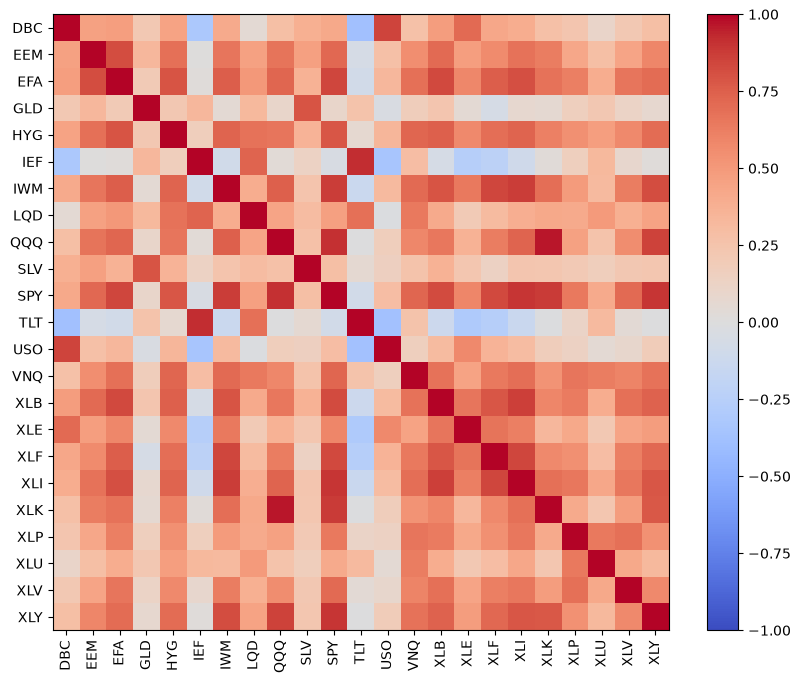

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.index)
plt.show()

<Axes: xlabel='Date'>

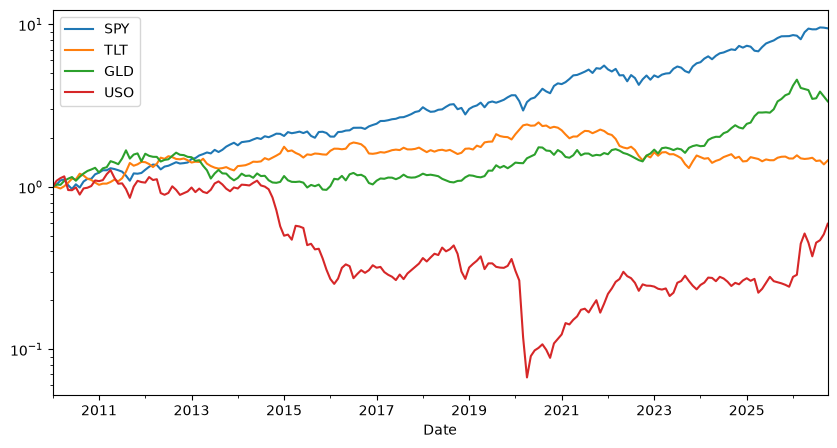

In [17]:
growth = (1 + monthly_returns.fillna(0)).cumprod()
growth[["SPY", "TLT", "GLD", "USO"]].plot(figsize=(10, 5), logy=True)

## Phase 2 summary: returns and exploration

- Built month-end prices (last trading day of each month) and monthly returns: 202 months x 23 ETFs, from 2010-02 to 2026-10. The partial November 2026 row was dropped.
- Hand-checked monthly returns against a calculator (DBC and GLD, Jan to Feb 2010).
- Annualized volatility (monthly std x sqrt(12)): lowest IEF 6.4%, LQD 7.3%, HYG 7.4%; SPY 14.3%; highest XLE 26.7%, SLV 32.3%, USO 37.8%.
- Correlation: equity ETFs and sectors sit around 0.7 to 0.9 with SPY (QQQ 0.91); TLT and IEF are about 0 (-0.08, -0.04); GLD is 0.10; HYG behaves like stocks (0.79).
- Implication: the 23 ETFs are not 23 independent bets. A momentum ranking will partly rank asset classes (stocks vs bonds vs commodities). To test later: ranking within each group, and the strategy's beta to SPY.
- Growth chart of SPY, TLT, GLD, USO matches known history (2020 crash, oil collapses, the 2026 gold surge).